# Problem 2 Actual-Error Paper Summary

This notebook is for paper reporting only. It uses saved Problem 2 results, keeps the final allocations and decision trees fixed, and reevaluates those fixed strategies with actual Helstrom branch probabilities. It does not generate new instances and does not re-optimize with actual error.

In [107]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import display

working_directory = Path.cwd()
project_directory = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
if str(project_directory) not in sys.path:
    sys.path.insert(0, str(project_directory))

import actual_error_analysis
actual_error_analysis = importlib.reload(actual_error_analysis)

run_actual_error_evaluation = actual_error_analysis.run_actual_error_evaluation
run_expanded_actual_error_evaluation = actual_error_analysis.run_expanded_actual_error_evaluation
actual_error_summary = actual_error_analysis.actual_error_summary
actual_method_comparison_summary = actual_error_analysis.actual_method_comparison_summary
expanded_actual_method_comparison_summary = actual_error_analysis.expanded_actual_method_comparison_summary
surrogate_quality_summary = actual_error_analysis.surrogate_quality_summary
bias_mae_summary = actual_error_analysis.bias_mae_summary
within_budget_correlation_summary = actual_error_analysis.within_budget_correlation_summary
method_ranking_agreement_summary = actual_error_analysis.method_ranking_agreement_summary
residual_by_k_summary = actual_error_analysis.residual_by_k_summary

print("Project directory:", project_directory)
print("Using actual_error_analysis from:", actual_error_analysis.__file__)

Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Using actual_error_analysis from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/actual_error_analysis.py


## Settings

Use `COMPACT_RUN_SCOPE` to switch between the saved compact pilot records and the saved full compact records. The compact analysis includes Exhaustive, Greedy, and Tree-aware heuristic because those strategies were all saved by the compact comparison pipeline. The optional expanded section is disabled by default and includes only Greedy and Tree-aware heuristic because the expanded data set has no Exhaustive-search solution.

In [108]:
# Compact data: includes Exhaustive, Greedy, and Tree-aware heuristic.
COMPACT_DATASETS = ("compact_benchmark_1d", "compact_benchmark_2d")
COMPACT_RUN_SCOPE = "full"  # switch to "test" for a quick pilot

# Expanded data: no Exhaustive solution exists, so only Greedy and Heuristic are shown.
RUN_EXPANDED_FULL = True
EXPANDED_DATASETS = ("benchmark_1d", "benchmark_2d")
EXPANDED_RUN_SCOPE = "full"

if COMPACT_RUN_SCOPE not in {"test", "full"}:
    raise ValueError('COMPACT_RUN_SCOPE must be "test" or "full"')
if EXPANDED_RUN_SCOPE not in {"test", "full"}:
    raise ValueError('EXPANDED_RUN_SCOPE must be "test" or "full"')

COMPACT_RESULTS_ROOT = project_directory / "results" / "algorithm_comparison_compact"
EXPANDED_RESULTS_ROOT = project_directory / "results" / "algorithm_comparison"
ACTUAL_RESULTS_ROOT = project_directory / "results" / "actual_error_evaluation"

print("Compact scope:", COMPACT_RUN_SCOPE)
print("Expanded enabled:", RUN_EXPANDED_FULL)
print("Reading compact saved allocations/trees from:", COMPACT_RESULTS_ROOT)
print("Writing paper outputs under:", ACTUAL_RESULTS_ROOT)

Compact scope: full
Expanded enabled: True
Reading compact saved allocations/trees from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/algorithm_comparison_compact
Writing paper outputs under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/actual_error_evaluation


## Compute Compact Actual Errors

This cell loads the saved compact allocations and decision trees from the previous Problem 2 comparison run. It then reevaluates each fixed tree with actual Helstrom branch probabilities. The progress messages count raw method-run records, not newly generated problem instances.

In [109]:
PROGRESS_EVERY = 100 if COMPACT_RUN_SCOPE == "full" else 25

compact_records_by_dataset = run_actual_error_evaluation(
    COMPACT_DATASETS,
    comparison_results_root=COMPACT_RESULTS_ROOT,
    results_root=ACTUAL_RESULTS_ROOT,
    run_scope=COMPACT_RUN_SCOPE,
    progress_every=PROGRESS_EVERY,
)

for dataset, records in compact_records_by_dataset.items():
    print(dataset, "records:", len(records))

[1/2] Loading compact_benchmark_1d full records
[1/2] Evaluating 9996 records
compact_benchmark_1d: evaluated 1/9996 records
compact_benchmark_1d: evaluated 100/9996 records
compact_benchmark_1d: evaluated 200/9996 records
compact_benchmark_1d: evaluated 300/9996 records
compact_benchmark_1d: evaluated 400/9996 records
compact_benchmark_1d: evaluated 500/9996 records
compact_benchmark_1d: evaluated 600/9996 records
compact_benchmark_1d: evaluated 700/9996 records
compact_benchmark_1d: evaluated 800/9996 records
compact_benchmark_1d: evaluated 900/9996 records
compact_benchmark_1d: evaluated 1000/9996 records
compact_benchmark_1d: evaluated 1100/9996 records
compact_benchmark_1d: evaluated 1200/9996 records
compact_benchmark_1d: evaluated 1300/9996 records
compact_benchmark_1d: evaluated 1400/9996 records
compact_benchmark_1d: evaluated 1500/9996 records
compact_benchmark_1d: evaluated 1600/9996 records
compact_benchmark_1d: evaluated 1700/9996 records
compact_benchmark_1d: evaluated 18

## Paper Numbers: Compact Surrogate Quality

This table checks whether the surrogate is numerically close to the actual physical tree error. Bias is `mean(actual - surrogate)`, so positive values mean the surrogate underestimates the actual error on average. MAE is the average absolute discrepancy. Pearson and Spearman are computed from raw per-run errors, separately by dimension and method; the pooled values combine all three methods.

In [110]:
bias_rows = bias_mae_summary(compact_records_by_dataset)
quality_rows = surrogate_quality_summary(compact_records_by_dataset)
quality_by_method = {row["method"]: row for row in quality_rows}

print("| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |")
print("|---|---|---:|---:|---:|---:|")
for row in bias_rows:
    method = row["method"]
    dim_key = row["dimension"].lower()
    quality = quality_by_method[method]
    print(
        f"| {row['dimension']} | {method} | "
        f"{row['bias']:.6f} | {row['mae']:.6f} | "
        f"{quality[f'{dim_key}_pearson']:.4f} | "
        f"{quality[f'{dim_key}_spearman']:.4f} |"
    )

all_methods = quality_by_method["All methods"]
print("\nPooled across all three methods")
print("| Dimension | Pearson | Spearman |")
print("|---|---:|---:|")
print(f"| 1D | {all_methods['1d_pearson']:.4f} | {all_methods['1d_spearman']:.4f} |")
print(f"| 2D | {all_methods['2d_pearson']:.4f} | {all_methods['2d_spearman']:.4f} |")

| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |
|---|---|---:|---:|---:|---:|
| 1D | Exhaustive | 0.011358 | 0.040992 | 0.9456 | 0.9486 |
| 1D | Greedy | -0.024572 | 0.049934 | 0.9418 | 0.9369 |
| 1D | Heuristic | -0.000151 | 0.041034 | 0.9471 | 0.9438 |
| 2D | Exhaustive | 0.013873 | 0.041106 | 0.9553 | 0.9578 |
| 2D | Greedy | -0.022475 | 0.045592 | 0.9571 | 0.9557 |
| 2D | Heuristic | -0.000251 | 0.038208 | 0.9608 | 0.9590 |

Pooled across all three methods
| Dimension | Pearson | Spearman |
|---|---:|---:|
| 1D | 0.9445 | 0.9425 |
| 2D | 0.9570 | 0.9559 |


## Paper Numbers: Compact Robustness Checks

The first table recomputes Pearson and Spearman correlations within each fixed budget level, pooling methods and instances. This checks whether the high pooled correlation is merely caused by all methods improving as budget increases. The second table measures method-ranking agreement: for each instance and budget level, it asks whether the method with the lowest surrogate error is also a method with the lowest actual error.

In [111]:
print("Correlation within fixed budget level, pooled across methods")
print("| Dimension | Budget level | Mean rho | Pearson | Spearman |")
print("|---|---:|---:|---:|---:|")
for row in within_budget_correlation_summary(compact_records_by_dataset):
    print(
        f"| {row['dimension']} | {row['budget_level']} | "
        f"{row['mean_budget_ratio']:.4f} | "
        f"{row['pearson']:.4f} | {row['spearman']:.4f} |"
    )

print("\nMethod-ranking agreement")
print("| Dimension | Budget level | Runs | Agreement rate |")
print("|---|---:|---:|---:|")
for row in method_ranking_agreement_summary(compact_records_by_dataset):
    print(
        f"| {row['dimension']} | {row['budget_level']} | "
        f"{row['runs']} | {100 * row['agreement_rate']:.1f}% |"
    )

Correlation within fixed budget level, pooled across methods
| Dimension | Budget level | Mean rho | Pearson | Spearman |
|---|---:|---:|---:|---:|
| 1D | 1 | 0.1788 | 0.8960 | 0.8949 |
| 1D | 2 | 0.3344 | 0.8879 | 0.8737 |
| 1D | 3 | 0.4991 | 0.9123 | 0.9095 |
| 1D | 4 | 0.6344 | 0.9206 | 0.9259 |
| 2D | 1 | 0.1622 | 0.9245 | 0.9275 |
| 2D | 2 | 0.3021 | 0.9305 | 0.9239 |
| 2D | 3 | 0.4518 | 0.9417 | 0.9392 |
| 2D | 4 | 0.5735 | 0.9454 | 0.9472 |

Method-ranking agreement
| Dimension | Budget level | Runs | Agreement rate |
|---|---:|---:|---:|
| 1D | All | 9996 | 78.9% |
| 1D | 1 | 2520 | 67.4% |
| 1D | 2 | 2520 | 77.6% |
| 1D | 3 | 2509 | 82.9% |
| 1D | 4 | 2447 | 88.0% |
| 2D | All | 10019 | 79.7% |
| 2D | 1 | 2520 | 70.5% |
| 2D | 2 | 2520 | 78.1% |
| 2D | 3 | 2514 | 83.3% |
| 2D | 4 | 2465 | 87.2% |


## Paper Numbers: Compact Actual-Error Algorithm Performance

This table compares algorithm conclusions after replacing the surrogate evaluation with actual Helstrom branch probabilities. The Exhaustive column is the surrogate-exhaustive solution reevaluated with actual error; it is not an actual-error optimum. The Tree-aware reduction column measures improvement over Greedy under actual error, and the final column measures how far Tree-aware remains from the surrogate-exhaustive solution.

In [112]:
print("| Dataset | Runs | Exhaustive actual | Greedy actual | Tree-aware actual | Tree-aware reduction vs Greedy | Tree-aware gap vs Exhaustive |")
print("|---|---:|---:|---:|---:|---:|---:|")
for dataset, records in compact_records_by_dataset.items():
    row = actual_method_comparison_summary(records)
    print(
        f"| {dataset} | {row['runs']} | "
        f"{row['optimal_mean_actual_error']:.6f} | "
        f"{row['greedy_mean_actual_error']:.6f} | "
        f"{row['tree_aware_mean_actual_error']:.6f} | "
        f"{row['tree_aware_actual_reduction_vs_greedy']:.6f} "
        f"({row['tree_aware_actual_reduction_vs_greedy_percent']:.1f}%) | "
        f"{row['tree_aware_actual_gap_vs_optimal']:.6f} |"
    )

| Dataset | Runs | Exhaustive actual | Greedy actual | Tree-aware actual | Tree-aware reduction vs Greedy | Tree-aware gap vs Exhaustive |
|---|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | 9996 | 0.222211 | 0.298690 | 0.294346 | 0.004345 (1.5%) | 0.072134 |
| compact_benchmark_2d | 10019 | 0.261755 | 0.339989 | 0.334266 | 0.005723 (1.7%) | 0.072512 |


## Paper Figures: Compact

This cell creates the two paper figures for the compact data. Figure 1 is the surrogate validation scatter: points near `y=x` mean the surrogate and actual errors agree numerically. Figure 2 is the actual-error performance curve: it shows whether Tree-aware still improves over Greedy when the fixed final strategies are evaluated with actual measurement probabilities.

- Figure 1: Surrogate validation


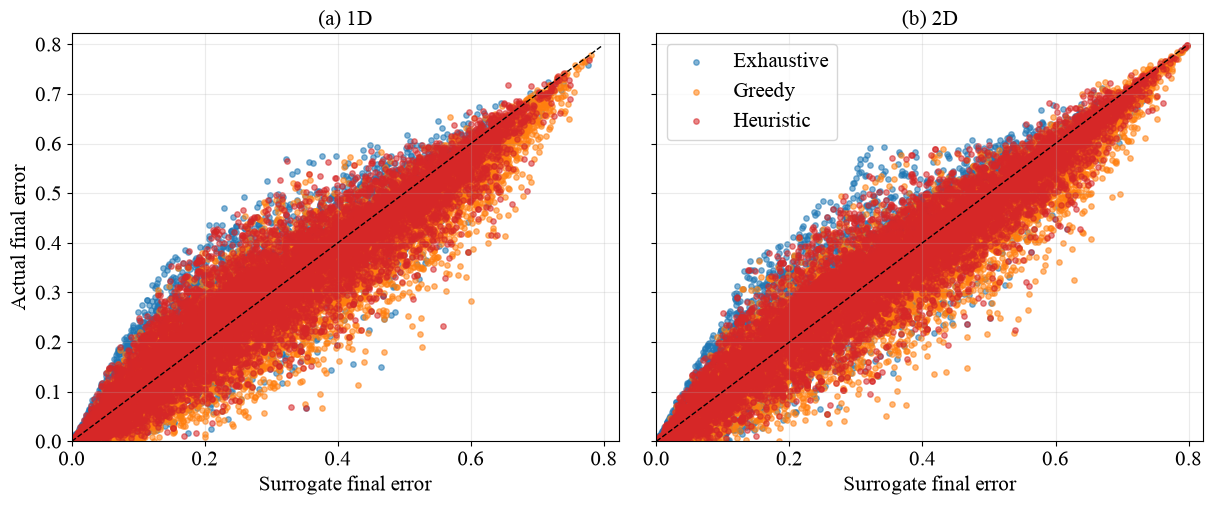

- Figure 2: Algorithm performance using actual error


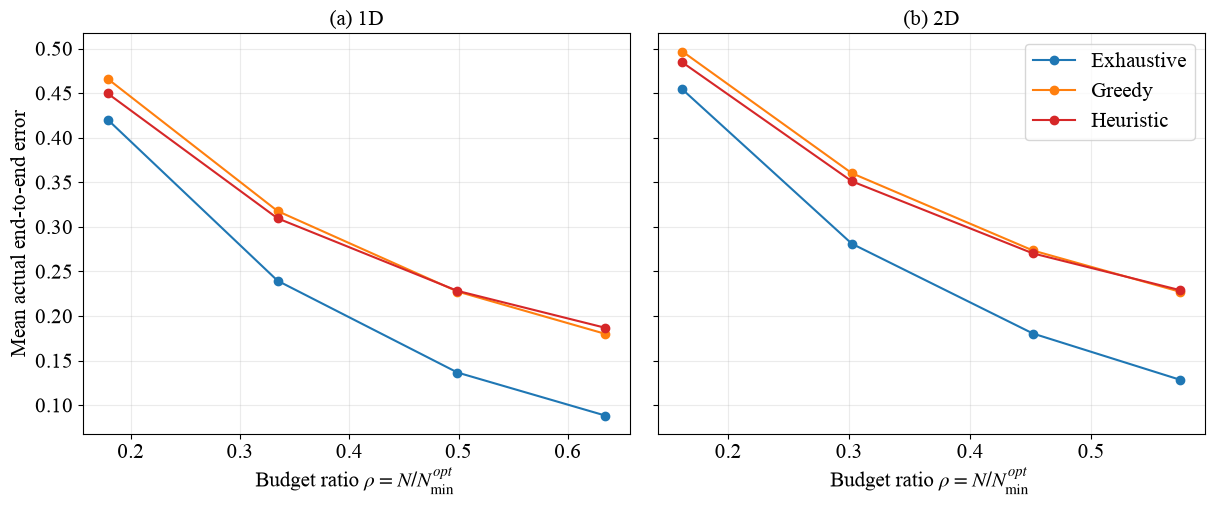

In [113]:
for title, figure in actual_error_analysis.make_combined_actual_error_plots(
    compact_records_by_dataset,
    ACTUAL_RESULTS_ROOT,
    run_scope=COMPACT_RUN_SCOPE,
):
    print("-", title)
    display(figure)
    plt.close(figure)

## Optional Expanded Full Check

This optional section repeats the same actual-error reevaluation on the saved expanded full benchmark. It is off by default because it is slower and because there is no Exhaustive-search solution for the expanded data. When enabled, it reports and plots only Greedy and Tree-aware heuristic.

In [114]:
if RUN_EXPANDED_FULL:
    expanded_records_by_dataset = run_expanded_actual_error_evaluation(
        EXPANDED_DATASETS,
        comparison_results_root=EXPANDED_RESULTS_ROOT,
        results_root=ACTUAL_RESULTS_ROOT,
        run_scope=EXPANDED_RUN_SCOPE,
        progress_every=250,
    )
    for dataset, records in expanded_records_by_dataset.items():
        print(dataset, "records:", len(records))
else:
    expanded_records_by_dataset = {}
    print("Expanded full check skipped. Set RUN_EXPANDED_FULL = True to run it.")

[1/2] Loading benchmark_1d full records
[1/2] Evaluating 10728 records
benchmark_1d: evaluated 1/10728 records
benchmark_1d: evaluated 250/10728 records
benchmark_1d: evaluated 500/10728 records
benchmark_1d: evaluated 750/10728 records
benchmark_1d: evaluated 1000/10728 records
benchmark_1d: evaluated 1250/10728 records
benchmark_1d: evaluated 1500/10728 records
benchmark_1d: evaluated 1750/10728 records
benchmark_1d: evaluated 2000/10728 records
benchmark_1d: evaluated 2250/10728 records
benchmark_1d: evaluated 2500/10728 records
benchmark_1d: evaluated 2750/10728 records
benchmark_1d: evaluated 3000/10728 records
benchmark_1d: evaluated 3250/10728 records
benchmark_1d: evaluated 3500/10728 records
benchmark_1d: evaluated 3750/10728 records
benchmark_1d: evaluated 4000/10728 records
benchmark_1d: evaluated 4250/10728 records
benchmark_1d: evaluated 4500/10728 records
benchmark_1d: evaluated 4750/10728 records
benchmark_1d: evaluated 5000/10728 records
benchmark_1d: evaluated 5250/107

In [115]:
if RUN_EXPANDED_FULL:
    print("Expanded surrogate quality: Greedy and Tree-aware only")
    print("| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |")
    print("|---|---|---:|---:|---:|---:|")
    expanded_bias = bias_mae_summary(
        expanded_records_by_dataset,
        methods=actual_error_analysis.EXPANDED_METHODS,
    )
    expanded_quality = surrogate_quality_summary(
        expanded_records_by_dataset,
        methods=actual_error_analysis.EXPANDED_METHODS,
    )
    expanded_quality_by_method = {row["method"]: row for row in expanded_quality}
    for row in expanded_bias:
        method = row["method"]
        dim_key = row["dimension"].lower()
        quality = expanded_quality_by_method[method]
        print(
            f"| {row['dimension']} | {method} | "
            f"{row['bias']:.6f} | {row['mae']:.6f} | "
            f"{quality[f'{dim_key}_pearson']:.4f} | "
            f"{quality[f'{dim_key}_spearman']:.4f} |"
        )

    print("\nExpanded actual-error algorithm performance")
    print("| Dataset | Runs | Greedy actual | Tree-aware actual | Tree-aware reduction vs Greedy |")
    print("|---|---:|---:|---:|---:|")
    for dataset, records in expanded_records_by_dataset.items():
        row = expanded_actual_method_comparison_summary(records)
        print(
            f"| {dataset} | {row['runs']} | "
            f"{row['greedy_mean_actual_error']:.6f} | "
            f"{row['heuristic_mean_actual_error']:.6f} | "
            f"{row['heuristic_actual_reduction_vs_greedy']:.6f} "
            f"({row['heuristic_actual_reduction_vs_greedy_percent']:.1f}%) |"
        )

Expanded surrogate quality: Greedy and Tree-aware only
| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |
|---|---|---:|---:|---:|---:|
| 1D | Greedy | -0.016052 | 0.047693 | 0.9491 | 0.9444 |
| 1D | Heuristic | 0.009572 | 0.043573 | 0.9497 | 0.9462 |
| 2D | Greedy | -0.015604 | 0.045215 | 0.9595 | 0.9583 |
| 2D | Heuristic | 0.009305 | 0.041142 | 0.9599 | 0.9590 |

Expanded actual-error algorithm performance
| Dataset | Runs | Greedy actual | Tree-aware actual | Tree-aware reduction vs Greedy |
|---|---:|---:|---:|---:|
| benchmark_1d | 10728 | 0.336674 | 0.327837 | 0.008837 (2.6%) |
| benchmark_2d | 10732 | 0.373173 | 0.363077 | 0.010095 (2.7%) |


- Expanded Figure 1: Surrogate validation


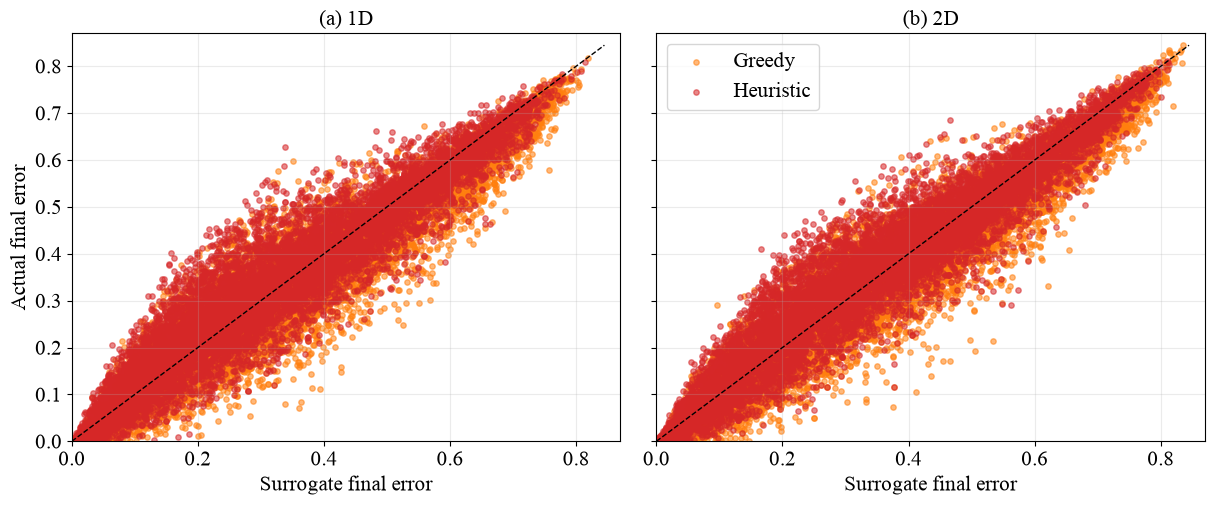

- Expanded Figure 2: Algorithm performance using actual error


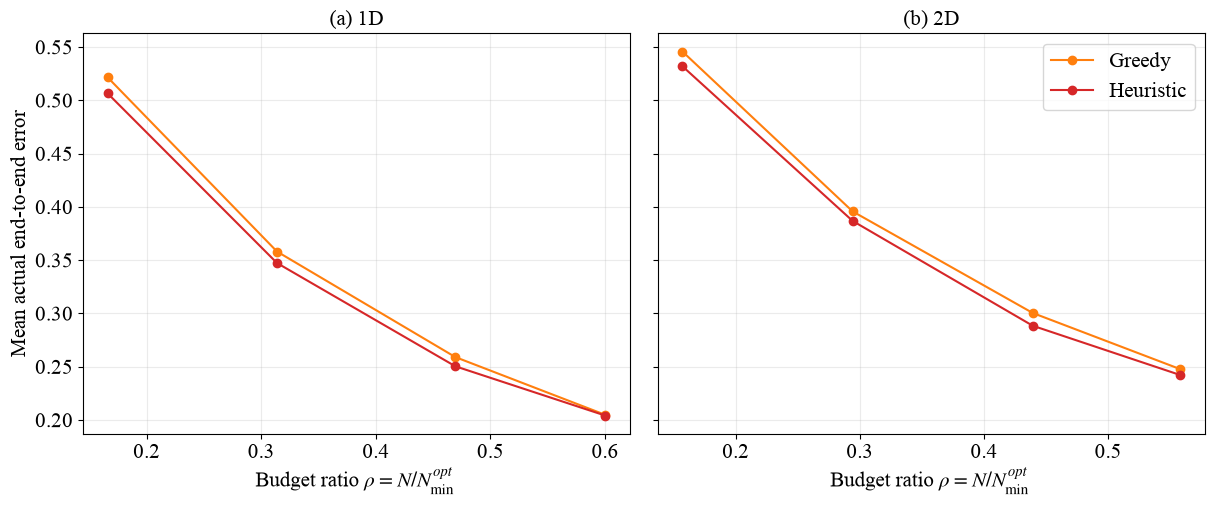

In [116]:
if RUN_EXPANDED_FULL:
    for title, figure in actual_error_analysis.make_combined_actual_error_plots(
        expanded_records_by_dataset,
        ACTUAL_RESULTS_ROOT,
        run_scope=f"expanded_{EXPANDED_RUN_SCOPE}",
        methods=actual_error_analysis.EXPANDED_METHODS,
    ):
        print("- Expanded", title)
        display(figure)
        plt.close(figure)

## Patterns To Report

Use this final cell as the paper-writing checklist. It summarizes which figures should appear in the paper and how to interpret the supporting numbers without overstating what the surrogate validation proves.

In [117]:
print("Paper figures to include")
print("1. Figure 1: surrogate final error vs actual final error, with 1D and 2D panels and y=x.")
print("2. Figure 2: mean actual end-to-end error vs budget ratio, with 1D and 2D panels.")

print("\nPaper-number checklist")
print("- Bias and MAE by dimension and method: calibration of the surrogate.")
print("- Pearson/Spearman by dimension and method, plus pooled all-method values: ranking proxy strength.")
print("- Within-budget Pearson/Spearman: checks whether pooled correlation is driven only by budget trend.")
print("- Method-ranking agreement: how often surrogate-best is also actual-best.")
print("- Mean actual errors and Tree-aware reduction vs Greedy: whether conclusions survive actual evaluation.")

print("\nInterpretation patterns")
print("- High correlation supports the surrogate as a ranking proxy, not as exact calibration.")
print("- Bias > 0 means the surrogate underestimates actual error on average; bias < 0 means it overestimates.")
print("- If within-budget correlations remain high, the relationship is not only due to the shared decrease with budget.")
print("- If Tree-aware actual error is below Greedy, the algorithmic ranking survives actual-error reevaluation.")
print("- The Exhaustive curve is surrogate-exhaustive reevaluated with actual error, not an actual-error optimum.")

Paper figures to include
1. Figure 1: surrogate final error vs actual final error, with 1D and 2D panels and y=x.
2. Figure 2: mean actual end-to-end error vs budget ratio, with 1D and 2D panels.

Paper-number checklist
- Bias and MAE by dimension and method: calibration of the surrogate.
- Pearson/Spearman by dimension and method, plus pooled all-method values: ranking proxy strength.
- Within-budget Pearson/Spearman: checks whether pooled correlation is driven only by budget trend.
- Method-ranking agreement: how often surrogate-best is also actual-best.
- Mean actual errors and Tree-aware reduction vs Greedy: whether conclusions survive actual evaluation.

Interpretation patterns
- High correlation supports the surrogate as a ranking proxy, not as exact calibration.
- Bias > 0 means the surrogate underestimates actual error on average; bias < 0 means it overestimates.
- If within-budget correlations remain high, the relationship is not only due to the shared decrease with budget.
- 